In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import re

In [3]:
DATASET_DIR = Path("att_faces")

print("Dataset path:", DATASET_DIR.resolve())
print("Folder exists:", DATASET_DIR.exists())

Dataset path: D:\ML\DS605_Lab7\att_faces
Folder exists: True


## PART A

In [4]:
images = []
labels = []
file_paths = []

subject_dirs = sorted(
    [p for p in DATASET_DIR.iterdir()
     if p.is_dir() and re.fullmatch(r"s\d+", p.name, flags=re.I)],
    key=lambda p: int(re.search(r"\d+", p.name).group())
)

for subject_dir in subject_dirs:
    image_files = sorted(
        subject_dir.glob("*.pgm"),
        key=lambda p: int(p.stem) if p.stem.isdigit() else p.stem
    )

    for image_path in image_files:
        with Image.open(image_path) as img:
            gray_image = img.convert("L")
            image_array = np.asarray(gray_image, dtype=np.float64)

        images.append(image_array)
        labels.append(int(re.search(r"\d+", subject_dir.name).group()))
        file_paths.append(image_path)

images = np.stack(images)
labels = np.array(labels)

print("Number of images:", len(images))
print("Number of subjects:", len(np.unique(labels)))
print("Image dimensions:", images.shape[1:])
print("Images array shape:", images.shape)
print("Labels shape:", labels.shape)

Number of images: 400
Number of subjects: 40
Image dimensions: (112, 92)
Images array shape: (400, 112, 92)
Labels shape: (400,)


In [5]:
X = images.reshape(len(images), -1)
y = labels

print("Image matrix shape:", X.shape)
print("Number of features per image:", X.shape[1])
print("Pixel intensity range:", X.min(), "to", X.max())

Image matrix shape: (400, 10304)
Number of features per image: 10304
Pixel intensity range: 0.0 to 251.0


In [6]:
RANDOM_SEED = 42
TRAIN_PER_SUBJECT = 7

rng = np.random.default_rng(RANDOM_SEED)

train_indices = []
test_indices = []

for subject in np.unique(y):
    subject_indices = np.where(y == subject)[0]
    rng.shuffle(subject_indices)

    train_indices.extend(subject_indices[:TRAIN_PER_SUBJECT])
    test_indices.extend(subject_indices[TRAIN_PER_SUBJECT:])

train_indices = np.array(sorted(train_indices))
test_indices = np.array(sorted(test_indices))

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)
print("Subjects in training:", len(np.unique(y_train)))
print("Subjects in testing:", len(np.unique(y_test)))

Training data shape: (280, 10304)
Testing data shape: (120, 10304)
Training labels shape: (280,)
Testing labels shape: (120,)
Subjects in training: 40
Subjects in testing: 40


## PART B

Mean face vector shape: (10304,)


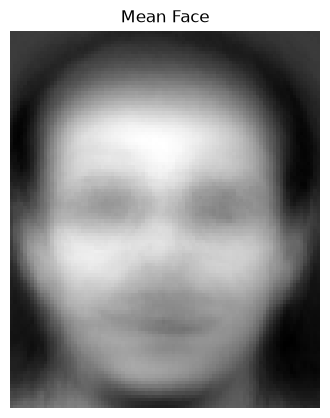

In [7]:
# Calculate the mean face using training images only
mean_face = np.mean(X_train, axis=0)

print("Mean face vector shape:", mean_face.shape)

# Convert the mean vector back into image dimensions
mean_face_image = mean_face.reshape(images.shape[1:])

plt.figure(figsize=(4, 5))
plt.imshow(mean_face_image, cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.show()

In [8]:
# Subtract the mean face from training and test images
X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

print("Centered training shape:", X_train_centered.shape)
print("Centered testing shape:", X_test_centered.shape)

print("Mean of centered training data:",
      np.mean(X_train_centered))

print("Minimum centered pixel value:",
      X_train_centered.min())

print("Maximum centered pixel value:",
      X_train_centered.max())

Centered training shape: (280, 10304)
Centered testing shape: (120, 10304)
Mean of centered training data: 0.0
Minimum centered pixel value: -155.67857142857142
Maximum centered pixel value: 176.70357142857142


In [9]:
# Step 1: Calculate the dual covariance matrix
n = X_train_centered.shape[0]

G = (X_train_centered @ X_train_centered.T) / (n - 1)

print("Dual covariance matrix shape:", G.shape)

# Step 2: Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(G)

print("Eigenvalues shape:", eigenvalues.shape)
print("Eigenvectors shape:", eigenvectors.shape)

# Step 3: Sort eigenvalues in descending order
order = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# Step 4: Remove tiny or non-positive eigenvalues
valid = eigenvalues > 1e-10

eigenvalues = eigenvalues[valid]
eigenvectors = eigenvectors[:, valid]

# Step 5: Convert eigenvectors into pixel-space principal directions
components_cov = X_train_centered.T @ eigenvectors

# Normalize each component to unit length
components_cov = components_cov / np.linalg.norm(
    components_cov, axis=0
)

# Convert to shape (number of components, number of pixels)
components_cov = components_cov.T

print("Principal components shape:", components_cov.shape)
print("First five eigenvalues:")
print(eigenvalues[:5])

Dual covariance matrix shape: (280, 280)
Eigenvalues shape: (280,)
Eigenvectors shape: (280, 280)
Principal components shape: (279, 10304)
First five eigenvalues:
[2846098.67866021 2016980.25535687 1133661.8885755   917097.62028599
  814513.20965583]


In [10]:
# Perform Singular Value Decomposition
U_svd, singular_values, Vt_svd = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

# Calculate PCA eigenvalues from singular values
n = X_train_centered.shape[0]

eigenvalues_svd = (singular_values ** 2) / (n - 1)

# Principal directions obtained from SVD
components_svd = Vt_svd

print("U shape:", U_svd.shape)
print("Singular values shape:", singular_values.shape)
print("V transpose shape:", Vt_svd.shape)
print("SVD components shape:", components_svd.shape)

print("First five SVD eigenvalues:")
print(eigenvalues_svd[:5])

U shape: (280, 280)
Singular values shape: (280,)
V transpose shape: (280, 10304)
SVD components shape: (280, 10304)
First five SVD eigenvalues:
[2846098.67866021 2016980.25535687 1133661.8885755   917097.62028599
  814513.20965584]


In [11]:
print("Covariance eigenvalues:")
print(eigenvalues[:5])

print("\nSVD eigenvalues:")
print(eigenvalues_svd[:5])

Covariance eigenvalues:
[2846098.67866021 2016980.25535687 1133661.8885755   917097.62028599
  814513.20965583]

SVD eigenvalues:
[2846098.67866021 2016980.25535687 1133661.8885755   917097.62028599
  814513.20965584]


In [12]:
# Compare the first 10 corresponding principal directions
num_compare = 10

similarities = np.abs(
    np.sum(
        components_cov[:num_compare] *
        components_svd[:num_compare],
        axis=1
    )
)

print("Absolute cosine similarities:")
print(np.round(similarities, 6))

Absolute cosine similarities:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Minimum components for 90% variance: 92
Cumulative variance retained: 0.900366437366489


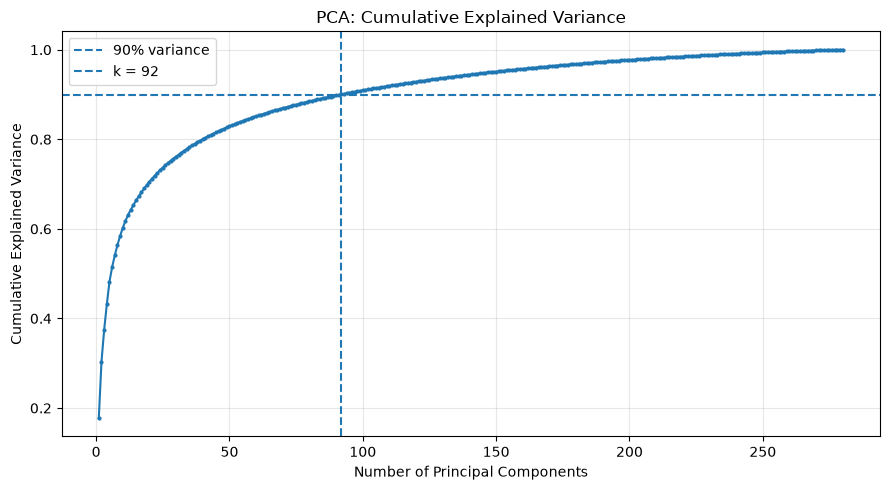

In [13]:
# Calculate explained variance ratio
explained_variance_ratio = (
    eigenvalues_svd / np.sum(eigenvalues_svd)
)

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(
    explained_variance_ratio
)

# Find the minimum number of components needed for 90% variance
k_90 = np.searchsorted(
    cumulative_variance, 0.90
) + 1

print("Minimum components for 90% variance:", k_90)
print(
    "Cumulative variance retained:",
    cumulative_variance[k_90 - 1]
)

# Plot cumulative explained variance
plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker=".",
    markersize=4
)

plt.axhline(
    y=0.90,
    linestyle="--",
    label="90% variance"
)

plt.axvline(
    x=k_90,
    linestyle="--",
    label=f"k = {k_90}"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA: Cumulative Explained Variance")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

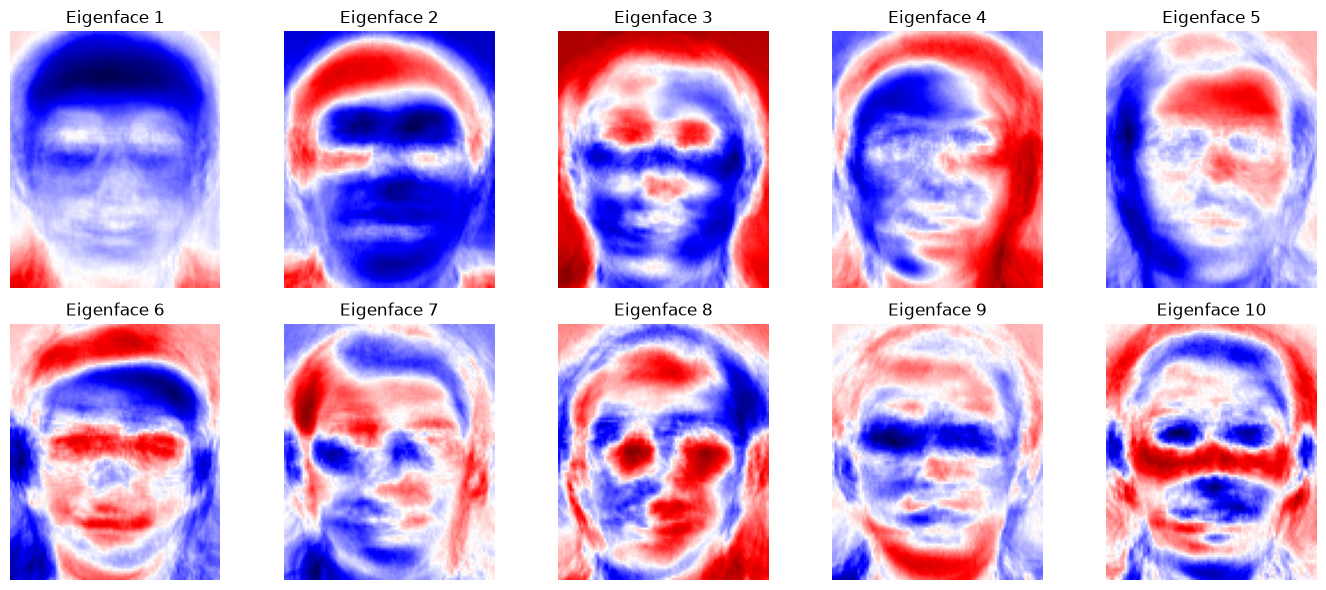

In [16]:
# Select the first 10 eigenfaces
n_eigenfaces = 10

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for i, ax in enumerate(axes.flat):
    eigenface = components_svd[i].reshape(images.shape[1:])

    # Symmetric scale makes positive and negative values visible
    limit = np.max(np.abs(eigenface))

    ax.imshow(
        eigenface,
        cmap="seismic",
        vmin=-limit,
        vmax=limit
    )

    ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.savefig("eigenfaces.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
plt.savefig("eigenfaces.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [17]:
# Select the first 92 principal components
components_90 = components_svd[:k_90]

# Project training and test images into PCA space
Z_train_90 = X_train_centered @ components_90.T
Z_test_90 = X_test_centered @ components_90.T

print("Training PCA representation:", Z_train_90.shape)
print("Testing PCA representation:", Z_test_90.shape)

Training PCA representation: (280, 92)
Testing PCA representation: (120, 92)


Reconstructed test data shape: (120, 10304)


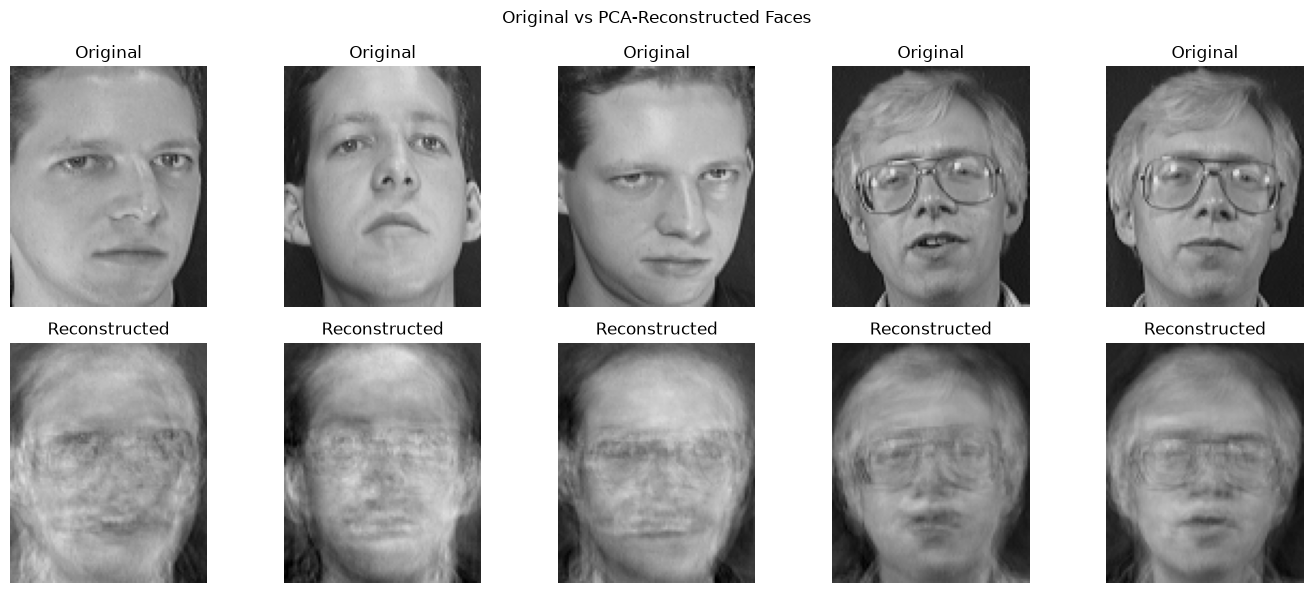

In [18]:
# Reconstruct test images from their PCA representations
X_test_reconstructed = (
    Z_test_90 @ components_90 + mean_face
)

print("Reconstructed test data shape:",
      X_test_reconstructed.shape)

# Compare the first five original and reconstructed faces
n_show = 5

fig, axes = plt.subplots(2, n_show, figsize=(14, 6))

for i in range(n_show):
    axes[0, i].imshow(
        X_test[i].reshape(images.shape[1:]),
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        np.clip(
            X_test_reconstructed[i].reshape(images.shape[1:]),
            0, 255
        ),
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.suptitle("Original vs PCA-Reconstructed Faces")
plt.tight_layout()
plt.savefig("reconstruction.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
mse = np.mean(
    (X_test - X_test_reconstructed) ** 2
)

rmse = np.sqrt(mse)

print("Reconstruction MSE:", mse)
print("Reconstruction RMSE:", rmse)

Reconstruction MSE: 335.524104799699
Reconstruction RMSE: 18.31731707427971


In [20]:
original_values = X_train.size
reduced_values = Z_train_90.size

reduction_percent = (
    1 - reduced_values / original_values
) * 100

print("Original pixel values:", original_values)
print("Reduced PCA values:", reduced_values)
print(f"Value-count reduction: {reduction_percent:.2f}%")

Original pixel values: 2885120
Reduced PCA values: 25760
Value-count reduction: 99.11%


## PART C

In [21]:
def nearest_neighbor_predict(X_reference, y_reference, X_query):
    # Calculate squared Euclidean distances
    distances_squared = (
        np.sum(X_query ** 2, axis=1, keepdims=True)
        + np.sum(X_reference ** 2, axis=1)[None, :]
        - 2 * X_query @ X_reference.T
    )

    distances_squared = np.maximum(distances_squared, 0)

    distances = np.sqrt(distances_squared)

    # Find the closest training image for each test image
    nearest_indices = np.argmin(distances, axis=1)

    # Predict the identity of the nearest training image
    predictions = y_reference[nearest_indices]

    return predictions, nearest_indices, distances


# Raw-pixel nearest-neighbor recognition
raw_predictions, raw_nn_indices, raw_distances = (
    nearest_neighbor_predict(X_train, y_train, X_test)
)

raw_accuracy = np.mean(raw_predictions == y_test)


# PCA nearest-neighbor recognition
pca_predictions, pca_nn_indices, pca_distances = (
    nearest_neighbor_predict(
        Z_train_90, y_train, Z_test_90
    )
)

pca_accuracy = np.mean(pca_predictions == y_test)


print(f"Raw-pixel accuracy: {raw_accuracy:.4f}")
print(f"PCA accuracy: {pca_accuracy:.4f}")

Raw-pixel accuracy: 0.9750
PCA accuracy: 0.9750


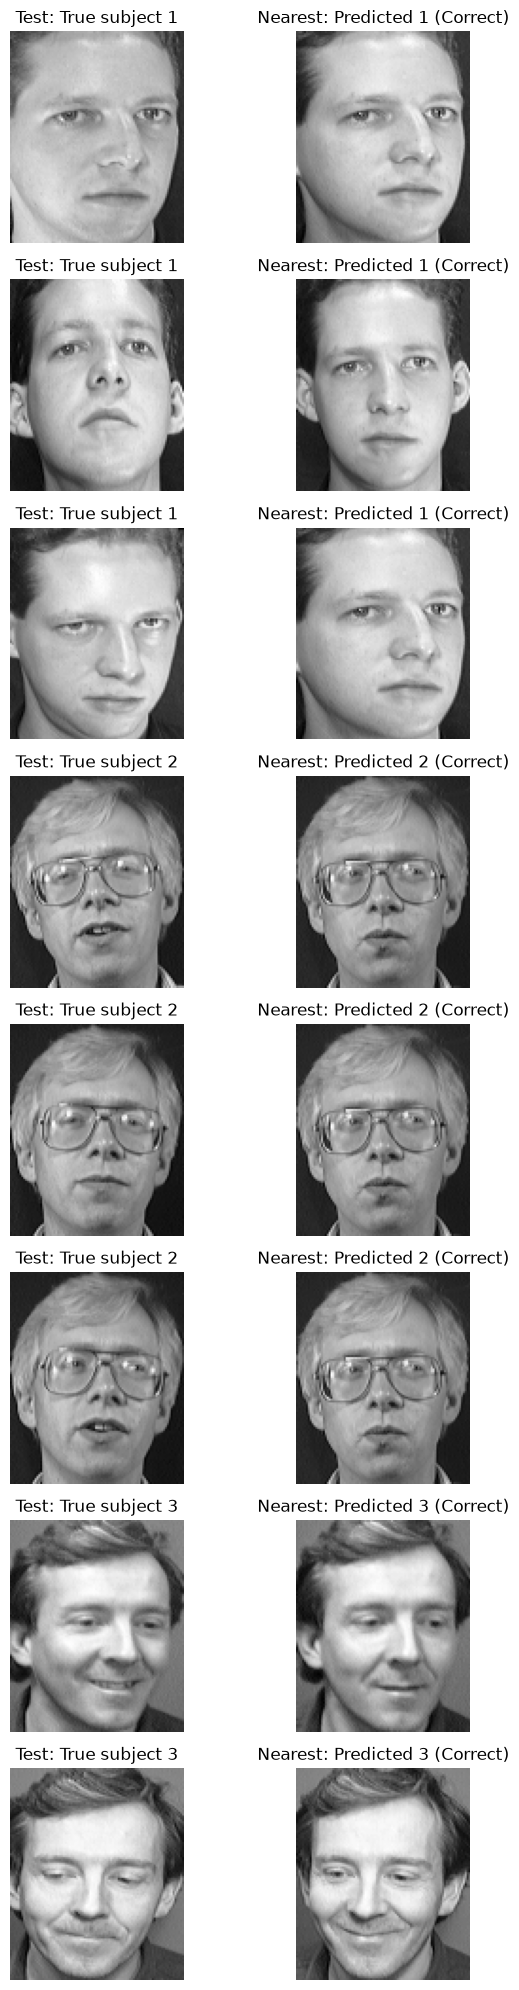

In [22]:
n_inspect = min(8, len(X_test))

fig, axes = plt.subplots(
    n_inspect, 2, figsize=(7, 2.5 * n_inspect)
)

for i in range(n_inspect):
    nearest_idx = pca_nn_indices[i]

    axes[i, 0].imshow(
        X_test[i].reshape(images.shape[1:]),
        cmap="gray"
    )
    axes[i, 0].set_title(
        f"Test: True subject {y_test[i]}"
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(
        X_train[nearest_idx].reshape(images.shape[1:]),
        cmap="gray"
    )

    correct = pca_predictions[i] == y_test[i]

    axes[i, 1].set_title(
        f"Nearest: Predicted {pca_predictions[i]} "
        f"({'Correct' if correct else 'Incorrect'})"
    )
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

## PART D

In [23]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Define the classifiers
models = {
    "KNN (k=1)": KNeighborsClassifier(n_neighbors=1),
    "KNN (k=3)": KNeighborsClassifier(n_neighbors=3),
    "Logistic Regression": LogisticRegression(max_iter=3000),
    "SVM (RBF)": SVC(kernel="rbf", C=10, gamma="scale")
}

results = []

# Train and evaluate each classifier
for name, model in models.items():
    model.fit(Z_train_90, y_train)

    predictions = model.predict(Z_test_90)

    accuracy = accuracy_score(y_test, predictions)

    results.append((name, accuracy))

    print(f"{name}: {accuracy:.4f} ({accuracy * 100:.2f}%)")

KNN (k=1): 0.9750 (97.50%)
KNN (k=3): 0.9083 (90.83%)
Logistic Regression: 0.9917 (99.17%)
SVM (RBF): 0.9833 (98.33%)


In [24]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

component_counts = [10, 20, 40, 60, 92, 120]

tuning_results = []

for k in component_counts:

    # Select the first k PCA directions
    components_k = components_svd[:k]

    # Project training and test images
    Z_train_k = X_train_centered @ components_k.T
    Z_test_k = X_test_centered @ components_k.T

    models = {
        "KNN (k=1)": KNeighborsClassifier(n_neighbors=1),
        "Logistic Regression": LogisticRegression(max_iter=3000),
        "SVM (RBF)": SVC(kernel="rbf", C=10, gamma="scale")
    }

    for name, model in models.items():
        model.fit(Z_train_k, y_train)
        predictions = model.predict(Z_test_k)

        accuracy = accuracy_score(y_test, predictions)

        tuning_results.append((k, name, accuracy))

for k, name, accuracy in tuning_results:
    print(f"Components: {k:3d} | {name:22s} | Accuracy: {accuracy:.4f}")

Components:  10 | KNN (k=1)              | Accuracy: 0.9500
Components:  10 | Logistic Regression    | Accuracy: 0.9417
Components:  10 | SVM (RBF)              | Accuracy: 0.9500
Components:  20 | KNN (k=1)              | Accuracy: 0.9500
Components:  20 | Logistic Regression    | Accuracy: 0.9917
Components:  20 | SVM (RBF)              | Accuracy: 0.9583
Components:  40 | KNN (k=1)              | Accuracy: 0.9750
Components:  40 | Logistic Regression    | Accuracy: 0.9750
Components:  40 | SVM (RBF)              | Accuracy: 0.9750
Components:  60 | KNN (k=1)              | Accuracy: 0.9750
Components:  60 | Logistic Regression    | Accuracy: 0.9583
Components:  60 | SVM (RBF)              | Accuracy: 0.9833
Components:  92 | KNN (k=1)              | Accuracy: 0.9750
Components:  92 | Logistic Regression    | Accuracy: 0.9917
Components:  92 | SVM (RBF)              | Accuracy: 0.9833
Components: 120 | KNN (k=1)              | Accuracy: 0.9833
Components: 120 | Logistic Regression   

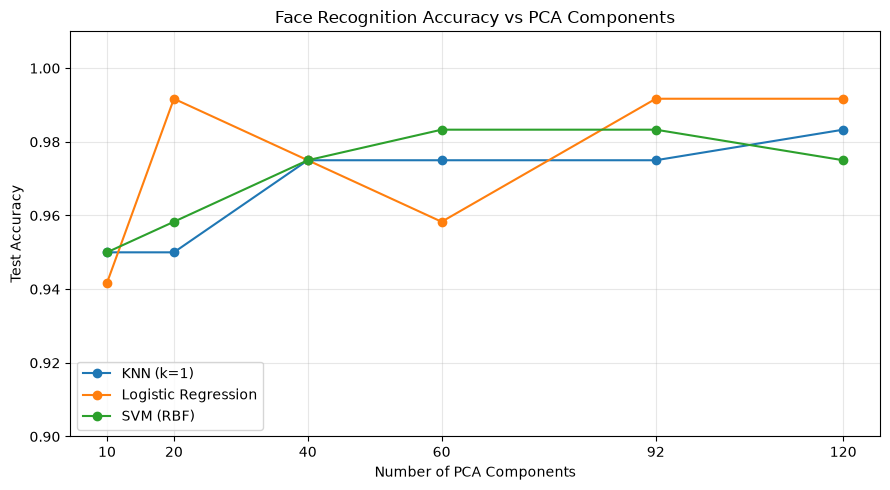

In [25]:
component_counts = [10, 20, 40, 60, 92, 120]

knn_scores = [0.9500, 0.9500, 0.9750, 0.9750, 0.9750, 0.9833]
lr_scores  = [0.9417, 0.9917, 0.9750, 0.9583, 0.9917, 0.9917]
svm_scores = [0.9500, 0.9583, 0.9750, 0.9833, 0.9833, 0.9750]

plt.figure(figsize=(9, 5))

plt.plot(component_counts, knn_scores, marker="o", label="KNN (k=1)")
plt.plot(component_counts, lr_scores, marker="o", label="Logistic Regression")
plt.plot(component_counts, svm_scores, marker="o", label="SVM (RBF)")

plt.xlabel("Number of PCA Components")
plt.ylabel("Test Accuracy")
plt.title("Face Recognition Accuracy vs PCA Components")
plt.xticks(component_counts)
plt.ylim(0.90, 1.01)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("classifier_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusion

In this assignment, the AT&T Database of Faces was used to study image representation, PCA, eigenfaces, face reconstruction, and face recognition. The dataset contained 400 grayscale images from 40 subjects, with each image represented by 10,304 pixel features.

PCA was implemented using both covariance/eigendecomposition and Singular Value Decomposition (SVD). The first five eigenvalues agreed to numerical precision, and the absolute cosine similarities of the first ten principal directions were all 1.0. A total of 92 principal components were required to retain 90.0366% of the training variance.

Using 92 components reduced the number of features per image by 99.11%. The reconstruction RMSE on the test images was approximately 18.32 intensity levels. Raw-pixel nearest-neighbor matching and PCA-space nearest-neighbor matching both achieved 97.50% accuracy.

Traditional classifiers were then evaluated using PCA features. Logistic Regression achieved the highest observed accuracy of 99.17%, including with 20 components. KNN and SVM also achieved strong results, although their performance varied with the number of retained components.

Overall, the experiment demonstrated that PCA can substantially reduce image dimensionality while preserving useful information for face recognition. The results also showed that the number of components maximizing explained variance does not necessarily maximize classification accuracy.
